# Figure 1 — panels (human dermal fibroblasts, young 10 yo vs old 75 yo)
Draws every Figure 1 / Supplementary Figure 1S panel from the tables in `data/` (written by `fibroblast_cohort.ipynb`
and `fibroblast_analysis.ipynb`; see README.md) → `figures/<panel>.{svg,png}`, named by final panel letter. Pages are assembled
in `fibroblast_pages.ipynb`. Sections follow the analyses; each final panel has its own header.

In [1]:
import sys

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, to_rgb
from matplotlib.legend_handler import HandlerTuple
from matplotlib.lines import Line2D
from matplotlib.offsetbox import AnchoredOffsetbox, DrawingArea, HPacker, TextArea, VPacker
from matplotlib.patches import Circle, FancyArrowPatch, Patch
from matplotlib.transforms import blended_transform_factory
from statsmodels.nonparametric.smoothers_lowess import lowess
import figstyle

sys.path.insert(0, "..")                                # shared modules
import kcore                                            # chromosome strips + paper-wide chromosome palette

figstyle.apply()
DATA = "data"
FIG = "figures"
SIG = 0.05

# paper palette (seaborn default): young blue, old red; shared and no-contact greys as Figs 4-6
palette = sns.color_palette().as_hex()
YOUNG = palette[0]
OLD = palette[3]
SHARED = "#B0B0B0"                                     # shared contacts
NONE = "#F2F2F2"                                       # no contact
GREY = "#9E9E9E"                                       # not significant

RENAME = [(" (H)", ""), ("Uv response", "UV response"), ("Dna repair", "DNA repair"), ("MTORC1", "mTORC1"),
          ("PI3K AKT MTOR", "PI3K-AKT-mTOR"), ("IL6 JAK STAT3", "IL6-JAK-STAT3"), ("IL2 STAT5", "IL2-STAT5"),
          ("TNF-alpha signaling via nfkb", "TNF-α signaling via NF-κB"), ("Interferon alpha", "Interferon-α"),
          ("Interferon gamma", "Interferon-γ"), ("TGF-beta", "TGF-β"), ("G2M", "G2/M"), ("WNT-beta", "WNT-β")]


def pretty(name):
    """Display name for a pathway (Hallmark suffix dropped, gene/protein symbols fixed)."""
    for old, new in RENAME:
        name = name.replace(old, new)
    return name


def save(fig, name):
    """Save a panel as editable SVG + PNG preview."""
    fig.savefig(f"{FIG}/{name}.svg", bbox_inches="tight")
    fig.savefig(f"{FIG}/{name}.png", dpi=200, bbox_inches="tight")

## Hi-C processing
### Figure 1a — Interchromosomal Hi-C to age-specific contacts
Interchromosomal Hi-C → LAS-processed binary contacts (one replicate per age) → age-specific map, pooled into 4 Mb blocks
(`data/fig1a_pooled_maps.npz`).

In [2]:
maps = np.load(f"{DATA}/fig1a_pooled_maps.npz")
mats = {key: maps[key] for key in maps.files if key != "chrom_starts"}
chrom_starts = maps["chrom_starts"].tolist()

TICK_CHROMS = (1, 5, 10, 15, 20)
S = 1.55                     # heatmap side (inches)
AF = 1.2                     # font scale: panel a is placed at ~0.82 on the page, so 7 x 1.2 here prints at ~7 pt
FW, FH = 9.6, 4.55           # figure size (inches)


def chrom_axes(ax, fs=7 * AF):
    """Chromosome ticks at selected chromosome starts, x labels at the bottom."""
    ticks = [chrom_starts[c - 1] for c in TICK_CHROMS]
    ax.set_xticks(ticks, [str(c) for c in TICK_CHROMS], fontsize=fs)
    ax.set_yticks(ticks, [str(c) for c in TICK_CHROMS], fontsize=fs)
    ax.xaxis.tick_bottom()
    ax.tick_params(length=2, pad=1)
    ax.set_xlabel("Chromosome", fontsize=fs + 1, labelpad=1)
    ax.set_ylabel("Chromosome", fontsize=fs + 1, labelpad=1)


def inch_axes(fig, x, y, w, h):
    """Axes placed in inches from the bottom-left corner of the figure."""
    return fig.add_axes([x / FW, y / FH, w / FW, h / FH])


def arrow(fig, start, end):
    """Black arrow between two points given in inches."""
    fig.add_artist(FancyArrowPatch((start[0] / FW, start[1] / FH), (end[0] / FW, end[1] / FH), transform=fig.transFigure,
                                   arrowstyle="-|>", mutation_scale=9, lw=1, color="black"))

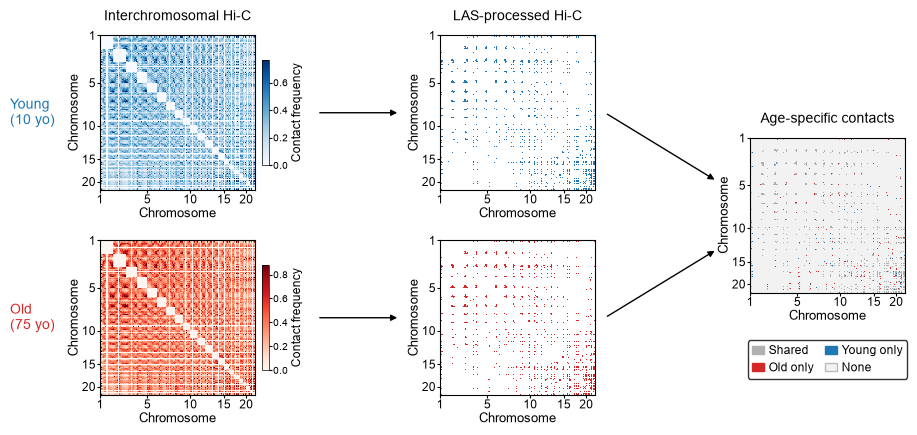

In [3]:
fig = plt.figure(figsize=(FW, FH))
row_y = {"young": 2.45, "old": 0.40}                   # bottom edge of each row (inches)
col_x = {"raw": 0.95, "las": 4.35, "age": 7.45}

for age, cmap_name, color in (("young", "Blues", YOUNG), ("old", "Reds", OLD)):
    y = row_y[age]
    raw = mats[f"{age}_raw"]
    vmax = np.percentile(raw[raw > 0], 99)
    ax = inch_axes(fig, col_x["raw"], y, S, S)
    im = ax.imshow(raw, cmap=cmap_name, vmin=0, vmax=vmax, interpolation="none")
    chrom_axes(ax)
    cax = inch_axes(fig, col_x["raw"] + S + 0.07, y + 0.25, 0.07, S - 0.5)
    cb = fig.colorbar(im, cax=cax)
    cb.ax.tick_params(labelsize=6 * AF, length=2, pad=1)
    cb.outline.set_linewidth(0.5)
    cb.set_label("Contact frequency", fontsize=7 * AF, labelpad=2)
    ax = inch_axes(fig, col_x["las"], y, S, S)
    ax.imshow(mats[f"{age}_las"], cmap=ListedColormap(["white", color]), vmin=0, vmax=1, interpolation="none")
    chrom_axes(ax)
    label = {"young": "Young\n(10 yo)", "old": "Old\n(75 yo)"}[age]
    fig.text(0.05 / FW, (y + S / 2) / FH, label, ha="left", va="center", fontsize=8.5 * AF, color=color)
    arrow(fig, (col_x["raw"] + S + 0.62, y + S / 2), (col_x["las"] - 0.40, y + S / 2))      # raw -> LAS

# age-specific map, centred between the two rows
age_y = (row_y["old"] + row_y["young"] + S) / 2 - S / 2
ax = inch_axes(fig, col_x["age"], age_y, S, S)
ax.imshow(mats["age_specific"], cmap=ListedColormap([NONE, YOUNG, OLD, SHARED]), vmin=-0.5, vmax=3.5,
          interpolation="none")
chrom_axes(ax)
ax.legend(handles=[Patch(color=SHARED, label="Shared"), Patch(color=OLD, label="Old only"),
                   Patch(color=YOUNG, label="Young only"), Patch(facecolor=NONE, edgecolor="#BBBBBB", label="None")],
          loc="upper center", bbox_to_anchor=(0.5, -0.27), ncol=2, frameon=True, edgecolor="black", fontsize=7 * AF,
          handlelength=1, columnspacing=1.0, handletextpad=0.4)
for age in ("young", "old"):                           # arrows: LAS -> age-specific map
    y0 = row_y[age] + S / 2
    y1 = age_y + S * (0.72 if age == "young" else 0.28)
    arrow(fig, (col_x["las"] + S + 0.1, y0), (col_x["age"] - 0.33, y1))

top = row_y["young"] + S + 0.12
for x, title in ((col_x["raw"], "Interchromosomal Hi-C"), (col_x["las"], "LAS-processed Hi-C")):
    fig.text((x + S / 2) / FW, top / FH, title, ha="center", va="bottom", fontsize=8.5 * AF)
fig.text((col_x["age"] + S / 2) / FW, (age_y + S + 0.12) / FH, "Age-specific contacts", ha="center",
         va="bottom", fontsize=8.5 * AF)
save(fig, "fig1a_hic_processing")
plt.show()

## Pathway colocalization
Per-state hypergeometric test on unique gene–gene contacts, BH FDR over the 60 pathways
(`data/fig1_pathway_colocalization_tss.csv`).

In [4]:
coloc = pd.read_csv(f"{DATA}/fig1_pathway_colocalization_tss.csv", index_col=0)

### Figure 1b — Colocalized pathways (Hi-C donors, 75 vs 10 yo)
Fold enrichment of young-only (left) and old-only (right) contacts vs the genome-wide share, for pathways at FDR < 0.05.

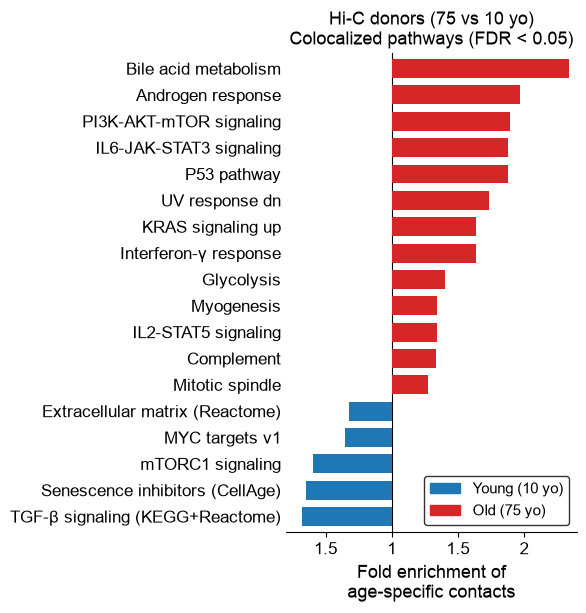

                                    fold_Young  fdr_Young  fold_Old  fdr_Old
TGF-beta signaling (KEGG+Reactome)      1.6743     0.0000    0.8617   1.0000
Senescence inhibitors (CellAge)         1.6504     0.0000    0.7414   1.0000
MTORC1 signaling (H)                    1.5983     0.0000    1.2647   0.0701
MYC targets v1 (H)                      1.3553     0.0017    0.8870   1.0000
Extracellular matrix (Reactome)         1.3253     0.0000    0.9668   1.0000
Mitotic spindle (H)                     0.5608     1.0000    1.2765   0.0142
Complement (H)                          0.9267     1.0000    1.3338   0.0238
IL2 STAT5 signaling (H)                 1.1083     0.6311    1.3428   0.0326
Myogenesis (H)                          0.6045     1.0000    1.3428   0.0025
Glycolysis (H)                          0.9406     1.0000    1.4031   0.0035
Interferon gamma response (H)           0.3657     1.0000    1.6352   0.0001
KRAS signaling up (H)                   0.8353     1.0000    1.6381   0.0010

In [5]:
young_sig = coloc.fdr_Young < SIG
old_sig = coloc.fdr_Old < SIG
bars_1b = pd.concat([coloc[young_sig & ~old_sig].sort_values("fold_Young", ascending=False),
                     coloc[old_sig].sort_values("fold_Old")])

fig, ax = plt.subplots(figsize=(6.0, 0.27 * len(bars_1b) + 1.4))
for i, (name, r) in enumerate(bars_1b.iterrows()):
    if r.fdr_Old < SIG:
        ax.barh(i, r.fold_Old - 1, left=1, height=0.72, color=OLD, zorder=3)
    if r.fdr_Young < SIG:
        ax.barh(i, -(r.fold_Young - 1), left=1, height=0.72, color=YOUNG, zorder=3)
ax.axvline(1, color="k", lw=0.8)
ax.set_xticks([0.5, 1, 1.5, 2], ["1.5", "1", "1.5", "2"], fontsize=12)   # mirrored: young fold to the left of 1
ax.set_xlim(0.2, 2.4)
ax.set_yticks(range(len(bars_1b)), [pretty(n) for n in bars_1b.index], fontsize=12)
ax.set_ylim(-0.6, len(bars_1b) - 0.4)
ax.set_xlabel("Fold enrichment of\nage-specific contacts", fontsize=13)
ax.set_title("Hi-C donors (75 vs 10 yo)\nColocalized pathways (FDR < 0.05)", fontsize=13)
ax.legend(handles=[Patch(color=YOUNG, label="Young (10 yo)"), Patch(color=OLD, label="Old (75 yo)")],
          loc="lower right", frameon=True, edgecolor="black", fontsize=11)
for sp in ("top", "right", "left"):
    ax.spines[sp].set_visible(False)
ax.tick_params(axis="y", length=0)
plt.tight_layout()
save(fig, "fig1b_colocalization")
plt.show()
print(bars_1b[["fold_Young", "fdr_Young", "fold_Old", "fdr_Old"]].round(4).to_string())

## Locus-matched permutation test
Each pathway against random gene-bearing loci matched for chromosome, gene density and expression
(`data/locus_matched_fibroblast.csv`).
### Supplementary Figure 1Sa — Locus-matched permutation test
−log10 nominal p for pathways with p ≤ 0.1 (young left, old right; full colour p < 0.05, light p ≤ 0.1).

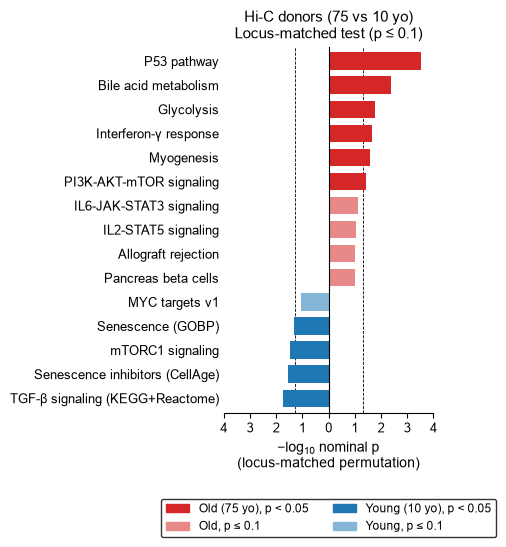

In [6]:
locus = pd.read_csv(f"{DATA}/locus_matched_fibroblast.csv")


def light(c, f=0.55):
    """Opaque tint of a colour (mixed toward white), so Illustrator sees a flat fill."""
    return tuple(1 - f * (1 - x) for x in to_rgb(c))


keep = locus[(locus.locus_p_Young <= 0.1) | (locus.locus_p_Old <= 0.1)]
old_side = keep.locus_p_Old <= keep.locus_p_Young                                   # pathway drawn in the old block
bars_1Sa = pd.concat([keep[~old_side].sort_values("locus_p_Young"),               # young block at the bottom
                      keep[old_side].sort_values("locus_p_Old", ascending=False)])  # old block on top
h = 0.26 * len(bars_1Sa) + 1.6
fig, ax = plt.subplots(figsize=(4.6, h))
for i, (_, r) in enumerate(bars_1Sa.iterrows()):
    for p, side, col in ((r.locus_p_Young, -1, YOUNG), (r.locus_p_Old, 1, OLD)):
        if p <= 0.1:
            ax.barh(i, side * -np.log10(p), height=0.72, color=col if p < 0.05 else light(col), zorder=3)
for s in (-1, 1):
    ax.axvline(s * -np.log10(0.05), color="black", lw=0.6, ls="--", zorder=2)
ax.axvline(0, color="black", lw=0.8, zorder=4)
min_p = bars_1Sa[["locus_p_Young", "locus_p_Old"]].min().min()
lim = max(2.0, np.ceil(-np.log10(min_p) + 0.3))
ticks = np.arange(0, lim + 0.01, 1)
tick_pos = np.r_[-ticks[:0:-1], ticks]                 # mirrored ticks: young to the left of 0
ax.set_xticks(tick_pos, [f"{abs(t):g}" for t in tick_pos], fontsize=9)
ax.set_xlim(-lim, lim)
ax.set_yticks(range(len(bars_1Sa)), [pretty(s) for s in bars_1Sa.set], fontsize=9.5)
ax.set_ylim(-0.6, len(bars_1Sa) - 0.4)
ax.set_xlabel("−log$_{10}$ nominal p\n(locus-matched permutation)", fontsize=10)
ax.set_title("Hi-C donors (75 vs 10 yo)\nLocus-matched test (p ≤ 0.1)", fontsize=11)
for sp in ("top", "right", "left"):
    ax.spines[sp].set_visible(False)
ax.tick_params(axis="y", length=0)
fig.legend(handles=[Patch(color=OLD, label="Old (75 yo), p < 0.05"), Patch(color=light(OLD), label="Old, p ≤ 0.1"),
                    Patch(color=YOUNG, label="Young (10 yo), p < 0.05"), Patch(color=light(YOUNG), label="Young, p ≤ 0.1")],
           loc="lower center", ncol=2, frameon=True, edgecolor="black", fontsize=8.5,
           # centred under the plot area (x in axes units), at the bottom of the figure (y in figure units)
           bbox_to_anchor=(0.5, 0),
           bbox_transform=blended_transform_factory(ax.transAxes, fig.transFigure))
plt.tight_layout(rect=(0, 0.55 / h, 1, 1))             # reserve ~0.55 in under the axis for the legend
save(fig, "fig1S_a_locus_matched")
plt.show()

## Pathway expression (GSEA)
Preranked GSEA on the DESeq2 Wald statistic (shared `gsea.py`, FDR < 0.05): the Hi-C donors (75 vs 10 yo;
`fibroblast_analysis.ipynb`) and the population cohort (61–96 vs 1–13 yo; `fibroblast_cohort.ipynb`). Positive NES = higher in old; dot size = FDR.

In [7]:
GSEA_FILES = {"75_vs_10_yo": f"{DATA}/75_vs_10_yo_gseapy/gseapy.gene_set.prerank.report.csv",
              "cohort_61_96": f"{DATA}/cohort_60plus_vs_young_gsea.csv"}
gsea = {}
for key, path in GSEA_FILES.items():
    g = pd.read_csv(path).set_index("Term")
    g["FDR q-val"] = pd.to_numeric(g["FDR q-val"])
    gsea[key] = g
    print(f"{key}: {(g['FDR q-val'] < SIG).sum()} pathways differentially expressed (FDR < {SIG})")


def p_size(q):
    """Lollipop dot size from GSEA FDR (Fig 5 / Fig 6 convention)."""
    return np.log(q + 0.005) * -3


def de_lollipop(gsea_df, title, name, width=6.0, xmax=3.6):
    """GSEA NES of the pathways at FDR < 0.05 (positive = higher in old); dot size = FDR. Saves figures/<name>."""
    de = gsea_df[gsea_df["FDR q-val"] < SIG].sort_values("NES")
    fig, ax = plt.subplots(figsize=(width, 0.27 * len(de) + 1.4))
    y = np.arange(len(de))
    ax.hlines(y, 0, de.NES, color="black", zorder=1)
    ax.scatter(de.NES, y, s=[p_size(max(q, 0.001)) ** 2 for q in de["FDR q-val"]],
               c=[OLD if v > 0 else YOUNG for v in de.NES], zorder=3)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_yticks(y, [pretty(n) for n in de.index], fontsize=12)
    ax.set_ylim(-0.6, len(de) - 0.4)
    ax.set_xlim(-xmax, xmax)
    ax.set_xticks([-2, 0, 2])
    ax.tick_params(axis="x", labelsize=12)
    ax.tick_params(axis="y", length=0)
    ax.set_xlabel("Normalized Enrichment Score\n(old vs young)", fontsize=13)
    ax.set_title(title, fontsize=13)
    size_legend = [Line2D([], [], color="black", marker="o", ls="none", markersize=p_size(q), label=f"  {lab}")
                   for q, lab in ((0.001, "≤0.001"), (0.05, "0.05"))]
    leg = ax.legend(handles=size_legend, title="GSEA FDR", loc="upper left", bbox_to_anchor=(1.02, 1.0), borderpad=1.0,
                    labelspacing=1.2, handlelength=0, handletextpad=1.2, fontsize=11, title_fontsize=11, edgecolor="black")
    ax.add_artist(leg)
    ax.legend(handles=[Patch(color=OLD, label="Higher in old"), Patch(color=YOUNG, label="Higher in young")],
              loc="lower left", bbox_to_anchor=(1.02, 0.0), frameon=True, edgecolor="black", fontsize=11)
    for sp in ("top", "right", "left"):
        ax.spines[sp].set_visible(False)
    plt.tight_layout()
    save(fig, name)
    plt.show()
    return de

75_vs_10_yo: 12 pathways differentially expressed (FDR < 0.05)
cohort_61_96: 28 pathways differentially expressed (FDR < 0.05)


### Supplementary Figure 1Sb — Differentially expressed pathways (Hi-C donors, 75 vs 10 yo)

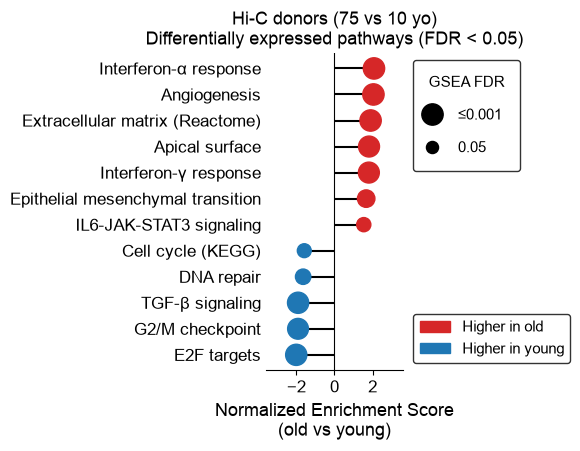

                                          NES  FDR q-val
Term                                                    
E2F targets (H)                       -2.0061     0.0012
G2M checkpoint (H)                    -1.9119     0.0018
TGF-beta signaling (H)                -1.9087     0.0012
Dna repair (H)                        -1.6445     0.0200
Cell cycle (KEGG)                     -1.5839     0.0306
IL6 JAK STAT3 signaling (H)            1.5378     0.0283
Epithelial mesenchymal transition (H)  1.6643     0.0102
Interferon gamma response (H)          1.8057     0.0016
Apical surface (H)                     1.8149     0.0016
Extracellular matrix (Reactome)        1.8958     0.0008
Angiogenesis (H)                       2.0457     0.0000
Interferon alpha response (H)          2.0738     0.0000


In [8]:
de = de_lollipop(gsea["75_vs_10_yo"], "Hi-C donors (75 vs 10 yo)\nDifferentially expressed pathways (FDR < 0.05)",
                 "fig1S_b_expression_donors")
print(de[["NES", "FDR q-val"]].round(4).to_string())

### Supplementary Figure 1Sd — Differentially expressed pathways (population cohort, 61–96 vs 1–13 yo)

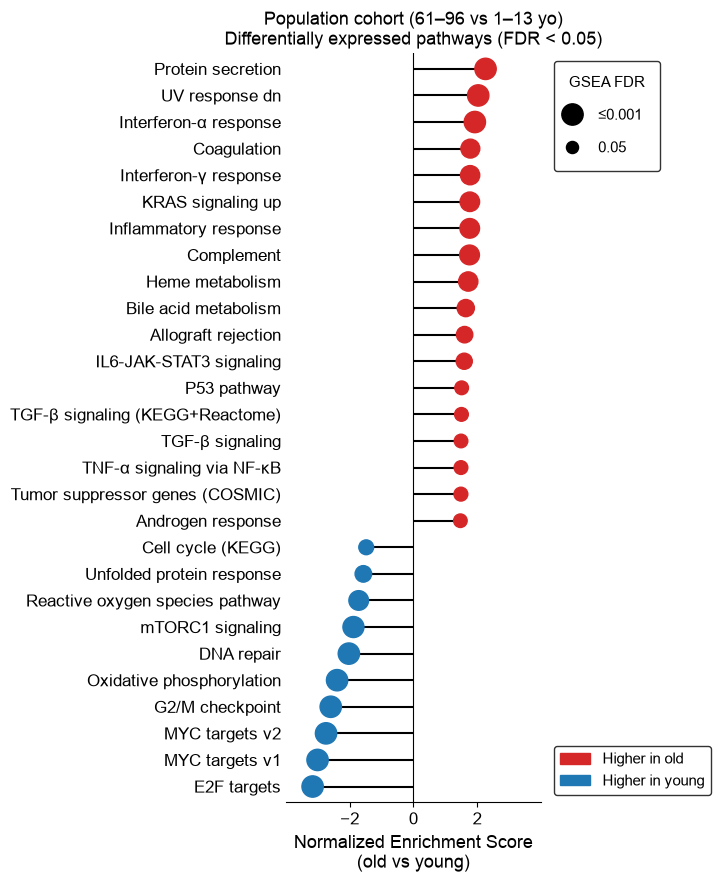

28 pathways at FDR < 0.05


In [9]:
cohort_de = de_lollipop(gsea["cohort_61_96"],
                        "Population cohort (61–96 vs 1–13 yo)\nDifferentially expressed pathways (FDR < 0.05)",
                        "fig1S_d_expression_cohort", width=7.4, xmax=4.0)     # wider axis: |NES| reaches 3.2
print(f"{len(cohort_de)} pathways at FDR < 0.05")

## Colocalization vs expression
x = GSEA NES (old vs young); y = log2(old fold / young fold) of age-specific contacts (the Fisher odds ratio). Colour =
per-state colocalization (FDR < 0.05); filled = differentially expressed (GSEA FDR < 0.05). Label positions are pinned in
data coordinates.

In [10]:
TITLES = {"75_vs_10_yo": "Hi-C donors (75 vs 10 yo)",
          "cohort_61_96": "Population cohort (61–96 vs 1–13 yo)"}
YLABEL = "Colocalization\nlog$_2$(old fold / young fold)"

# Labelled pathways per panel: colocalized & differentially expressed, all young-specific pathways, and the top
# colocalized-not-DE pathways. (label, pathways at that point, label position in data coordinates, horizontal alignment);
# the first pathway anchors the leader line, any others share the label because their points coincide
LABELS = {
    "75_vs_10_yo": [
        ("IL6-JAK-STAT3", ["IL6 JAK STAT3 signaling (H)"], (1.909, 2.826), "center"),
        ("IFN-γ", ["Interferon gamma response (H)"], (2.084, 2.111), "center"),
        ("Bile acid\nmetabolism", ["Bile acid metabolism (H)"], (0.659, 2.160), "center"),
        ("UV response dn", ["Uv response dn (H)"], (-0.812, 1.875), "center"),
        ("ECM", ["Extracellular matrix (Reactome)"], (2.120, -0.952), "center"),
        ("mTORC1", ["MTORC1 signaling (H)"], (1.428, -0.635), "center"),
        ("MYC targets v1", ["MYC targets v1 (H)"], (-0.432, -0.402), "center"),
        ("TGF-β", ["TGF-beta signaling (KEGG+Reactome)"], (-1.759, -1.134), "center"),
        ("Senescence\ninhibitors", ["Senescence inhibitors (CellAge)"], (0.019, -0.987), "center")],
    "cohort_61_96": [
        ("IL6-JAK-STAT3", ["IL6 JAK STAT3 signaling (H)"], (0.900, 2.750), "center"),
        ("IFN-γ", ["Interferon gamma response (H)"], (2.350, 2.550), "center"),
        ("Bile acid\nmetabolism", ["Bile acid metabolism (H)"], (1.150, 1.900), "right"),
        ("UV response dn", ["Uv response dn (H)"], (2.450, 1.550), "left"),
        ("P53, KRAS up", ["P53 pathway (H)", "KRAS signaling up (H)"], (1.000, 1.450), "right"),
        ("Complement", ["Complement (H)"], (2.400, 0.250), "center"),
        ("MYC targets v1", ["MYC targets v1 (H)"], (-2.250, -1.300), "center"),
        ("mTORC1", ["MTORC1 signaling (H)"], (-1.900, 0.150), "center"),
        ("Senescence\ninhibitors", ["Senescence inhibitors (CellAge)"], (-1.000, -1.650), "center"),
        ("ECM", ["Extracellular matrix (Reactome)"], (0.400, -0.850), "center"),
        ("TGF-β", ["TGF-beta signaling (KEGG+Reactome)"], (2.100, -1.300), "center")],
}

# colocalization: log2(old fold / young fold) = log2 Fisher odds ratio; colour = per-state significance
conc = coloc.copy()
conc["y"] = np.log2(conc.fisher_or)
# no pathway is significant in both states, so the order of the conditions does not matter
conc["color"] = np.select([conc.fdr_Old < SIG, conc.fdr_Young < SIG], [OLD, YOUNG], GREY)

/local_home/land/anaconda3/envs/cd8hic/lib/python3.12/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log2
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [11]:
def concordance_axes(ax, key, title, label_fs):
    """One comparison: pathways at (GSEA NES, log2 old/young fold), coloured by colocalization, filled if DE."""
    d = conc.join(gsea[key][["NES", "FDR q-val"]], how="inner")
    d = d[np.isfinite(d.y)]                                   # a set with 0 young- or old-only contacts has no ratio
    d["de"] = d["FDR q-val"] < SIG
    grey_first = d.sort_values("color", key=lambda c: c == GREY, ascending=False)   # coloured points drawn on top
    for _, r in grey_first.iterrows():
        ax.scatter(r.NES, r.y, s=30, facecolor=r.color if r.de else "white", edgecolor=r.color, lw=1.0,
                   zorder=2 if r.color == GREY else 3)
    for label, pathways_at, xy_text, ha in LABELS[key]:
        point = d.loc[pathways_at[0]]
        ax.annotate(label, (point.NES, point.y), xytext=xy_text, textcoords="data", fontsize=label_fs, ha=ha,
                    va="center", zorder=5, arrowprops=dict(arrowstyle="-", color="0.4", lw=0.5, shrinkA=1, shrinkB=2.5))
    ax.axhline(0, color="0.7", lw=0.7, ls=":")
    ax.axvline(0, color="0.7", lw=0.7, ls=":")
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Expression, old vs young\n(GSEA NES)", fontsize=10.5)
    ax.tick_params(labelsize=10)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)


def legend_entry(face, edge, label, fs):
    """One legend entry: a circle marker followed by its label."""
    da = DrawingArea(9, 9, 0, 0)
    da.add_artist(Circle((4.5, 4.5), 3.6, facecolor=face, edgecolor=edge, lw=1.0))
    return HPacker(children=[da, TextArea(label, textprops=dict(fontsize=fs))], align="center", pad=0, sep=4)


def legend_block(title, entries, fs):
    """A legend header with its entries on the line below."""
    return VPacker(children=[TextArea(title, textprops=dict(fontsize=fs)),
                             HPacker(children=entries, align="center", pad=0, sep=14)], align="center", pad=0, sep=4)


def legends_below(fig, ax, fs=10):
    """Colocalization and expression keys in ONE framed box under the plot, centred on the plot area."""
    coloc_key = legend_block("Colocalization (color; FDR < 0.05)",
                             [legend_entry(OLD, OLD, "Old-specific", fs), legend_entry(YOUNG, YOUNG, "Young-specific", fs),
                              legend_entry(GREY, GREY, "Not significant", fs)], fs)
    expr_key = legend_block("Expression (fill; GSEA FDR < 0.05)",
                            [legend_entry("0.3", "0.3", "Differentially expressed", fs),
                             legend_entry("white", "0.3", "Not differentially expressed", fs)], fs)
    box = AnchoredOffsetbox(loc="upper center", child=VPacker(children=[coloc_key, expr_key], align="center", pad=0, sep=9),
                            pad=0.5, borderpad=0, frameon=True, bbox_to_anchor=(0.5, 0.185),   # top of box just
                            # below the plot area, which tight_layout(rect=(0, 0.21, 1, 1)) ends at 21% of the height
                            bbox_transform=blended_transform_factory(ax.transAxes, fig.transFigure))
    box.patch.set_edgecolor("black")
    box.patch.set_boxstyle("square", pad=0)
    fig.add_artist(box)


def concordance_panel(key, name):
    """Colocalization-vs-expression scatter for one comparison, legends underneath; saves figures/<name>."""
    fig, ax = plt.subplots(figsize=(4.8, 5.4))
    concordance_axes(ax, key, TITLES[key], label_fs=10)
    ax.set_ylabel(YLABEL, fontsize=10.5)
    plt.tight_layout(rect=(0, 0.21, 1, 1))             # leave the bottom fifth for the legends
    legends_below(fig, ax)
    save(fig, name)
    plt.show()

### Figure 1c — Colocalization vs expression (Hi-C donors, 75 vs 10 yo)

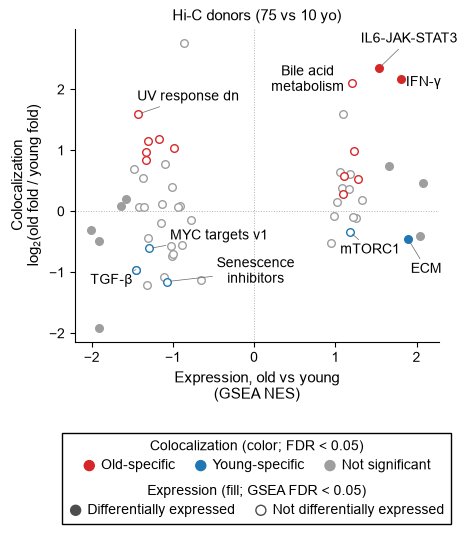

In [12]:
concordance_panel("75_vs_10_yo", "fig1c_concordance_donors")

### Supplementary Figure 1Sc — Hi-C donor colocalization vs population-cohort expression (61–96 vs 1–13 yo)

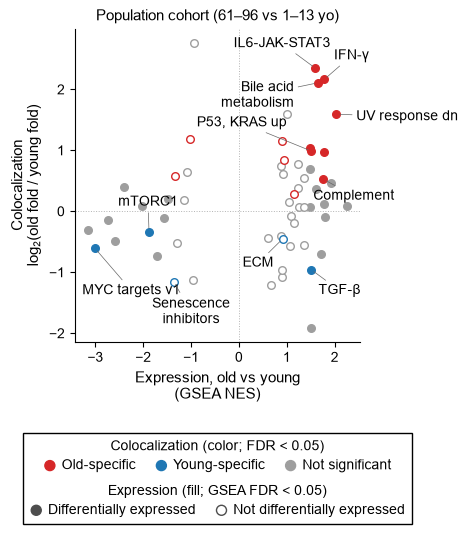

In [13]:
concordance_panel("cohort_61_96", "fig1S_c_concordance_cohort")

## Population cohort interferon score
### Figure 1d — Interferon-γ response score versus donor age
Per-donor interferon-γ score in the 133 healthy donors of the Fleischer cohort (1–96 yo): log2 CPM per gene, z-scored
across donors, averaged over the Hallmark set (`fibroblast_cohort.ipynb`). Curve = LOWESS fit (frac 0.5); Spearman ρ from
`fibroblast_analysis.ipynb`.

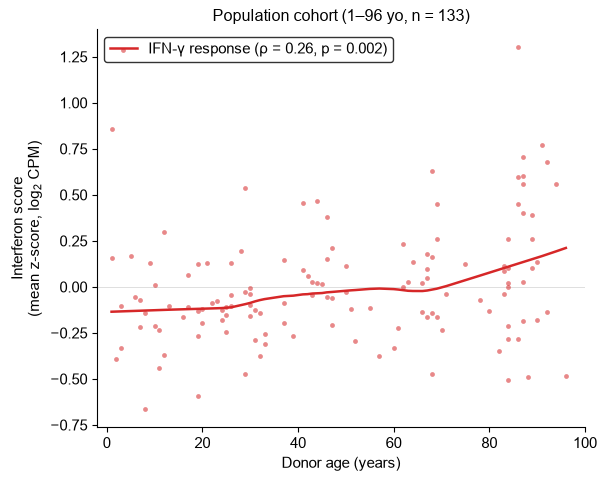

In [14]:
isg = pd.read_csv(f"{DATA}/cohort_isg_scores.csv", index_col=0)
stats = pd.read_csv(f"{DATA}/cohort_ifng_age_spearman.csv").iloc[0]

fig, ax = plt.subplots(figsize=(6.2, 4.95))           # sized to sit beside the IFN-γ core in Fig 1 at ~7 pt text
dots = ax.scatter(isg.Age, isg["IFN-γ response"], s=12, color=OLD, alpha=0.55, lw=0, zorder=2)
fit = lowess(isg["IFN-γ response"], isg.Age, frac=0.5)                   # sorted (age, fitted) pairs
line, = ax.plot(fit[:, 0], fit[:, 1], color=OLD, lw=1.8, zorder=3)
label = f"IFN-γ response (ρ = {stats.spearman_rho:.2f}, p = {stats.p:.1g})"
ax.axhline(0, color="0.85", lw=0.6, zorder=0)
ax.set_xlim(-2, 100)
ax.set_xlabel("Donor age (years)", fontsize=11)
ax.set_ylabel("Interferon score\n(mean z-score, log$_2$ CPM)", fontsize=11)
ax.set_title(f"Population cohort (1–96 yo, n = {len(isg)})", fontsize=11.5)
ax.tick_params(labelsize=10.5)
ax.legend([(line, dots)], [label], handler_map={tuple: HandlerTuple(ndivide=1)}, loc="upper left",   # curve with a dot
          frameon=True, edgecolor="black", fontsize=10.5, handlelength=1.8)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
plt.tight_layout()
save(fig, "fig1d_cohort_ifng_age")
plt.show()

## State-specific k-cores
Gene × gene contact-state heatmaps of the cores computed in `fibroblast_analysis.ipynb` (`data/kcores/`), genes in genomic
order, with chromosome strips (paper-wide chromosome palette; shared `../kcore.py`).

In [15]:
STATE_COLORS = [NONE, YOUNG, OLD, SHARED]              # contact-state codes 0 none, 1 young-only, 2 old-only, 3 shared
CORE_INFO = pd.read_csv(f"{DATA}/kcores/kcore_summary.csv").set_index("core")

def plot_core(core, title, name, size=4.6, fs=10, text_scale=1.0):
    """Contact-state heatmap of a saved k-core with chromosome strips and a one-line state legend; saves figures/<name>."""
    info = CORE_INFO.loc[core]
    genes = pd.read_csv(f"{DATA}/kcores/{core}_genes.csv")
    mat = pd.read_csv(f"{DATA}/kcores/{core}_states.csv", index_col=0).to_numpy()
    fig, ax = plt.subplots(figsize=(size, size))
    ax.matshow(mat, cmap=ListedColormap(STATE_COLORS), vmin=-0.5, vmax=3.5, aspect="equal")
    kcore.chrom_strips(ax, genes.gene.tolist(), genes.chrom.tolist(), fs)
    ax.set_title(f"{title} ({info.k}-core)", fontsize=12 * text_scale)
    plt.tight_layout()
    first = [Patch(color=OLD, label="Old only"), Patch(color=YOUNG, label="Young only")]
    if info.state == "Young":
        first = first[::-1]                            # the core's own state first
    fig.legend(handles=first + [Patch(color=SHARED, label="Shared"), Patch(facecolor=NONE, edgecolor="#BBBBBB", label="None")],
               loc="upper center", ncol=4, frameon=True, edgecolor="black", fontsize=10 * text_scale, handlelength=1,
               columnspacing=1.0,
               # centred under the heatmap (x in axes units, not the gene labels), at the bottom of the figure
               bbox_to_anchor=(0.5, 0.0), bbox_transform=blended_transform_factory(ax.transAxes, fig.transFigure))
    save(fig, name)
    plt.show()

In [16]:
print(CORE_INFO[["pathway", "state", "k", "n_core_genes", "n_chromosomes"]].to_string())

                                           pathway  state  k  n_core_genes  n_chromosomes
core                                                                                     
ifng_old_3core       Interferon gamma response (H)    Old  3            18              7
seninh_young_core  Senescence inhibitors (CellAge)  Young  4            22             11
ecm_young_core     Extracellular matrix (Reactome)  Young  6            37             11


### Figure 1e — Interferon-γ response, old-specific core
The 3-core (18 genes, 7 chromosomes) rather than the densest 4-core (11 genes on 3 chromosomes).

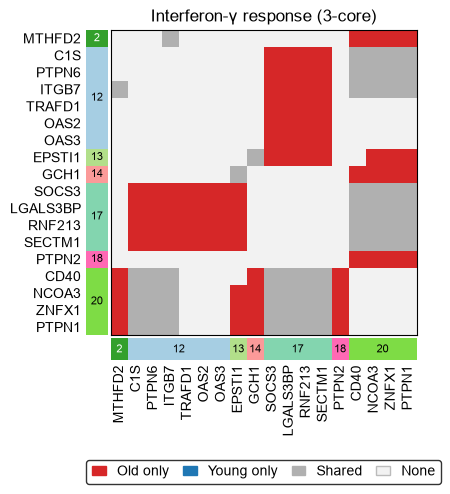

In [17]:
plot_core("ifng_old_3core", "Interferon-γ response", "fig1e_ifng_core")

### Supplementary Figure 1Se — Senescence inhibitors, young-specific core

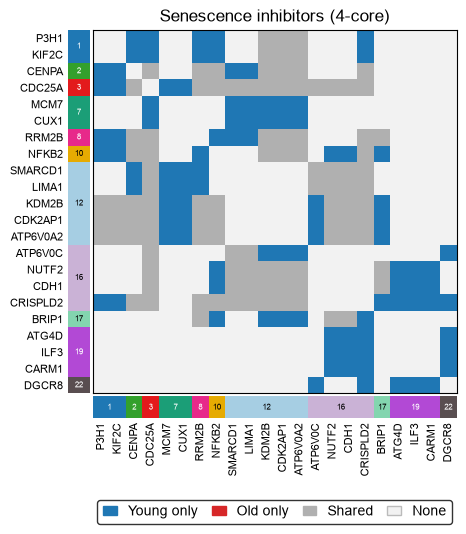

In [18]:
plot_core("seninh_young_core", "Senescence inhibitors", "fig1S_e_seninh_core", size=5.0, fs=8)

### Supplementary Figure 1Sf — Extracellular matrix, young-specific core
Larger canvas than 1Se and scaled down more on the page, so the title and legend are drawn larger to match.

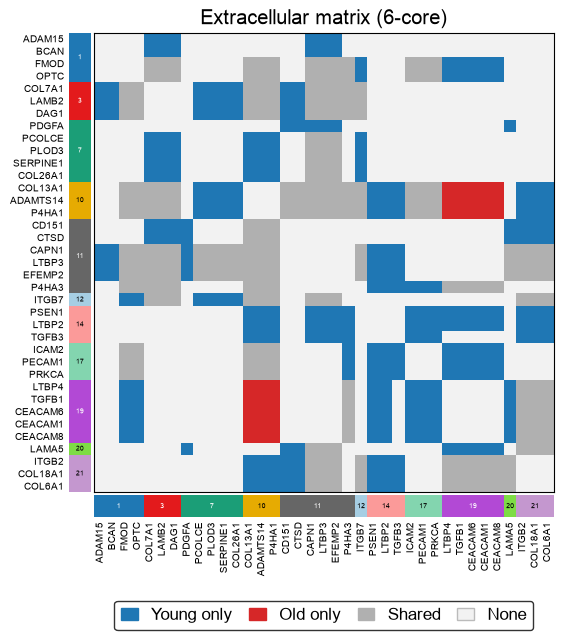

In [19]:
plot_core("ecm_young_core", "Extracellular matrix", "fig1S_f_ecm_core", size=6.0, fs=7, text_scale=6.0 / 5.0)